### 💡 데이터 분포 분석 (Data Distribution)
데이터 분포는 데이터 값들이 어떤 범위에 얼마나 많이 존재하는지를 나타내는 개념이다.

#### 사분위수(Quartile)
**사분위수**는 데이터를 크기순으로 정렬한 다음, 전체 데이터를 네 구간으로 나누는 기준값이다.

세 가지 기준값이 있다.
- Q1(제1사분위수) : 하위 25%지점
- Q2(제2사분위수) : 하위 50%지점(중앙값)
- Q3(제3사분위수) : 하위 75%지점

In [2]:
# 실제 데이터에서 사분위수 구하기
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("./datasets/titanic.csv")

# 나이의 사분위수 확인
print(df["age"].quantile([0.25, 0.5, 0.75]))

0.25    20.125
0.50    28.000
0.75    38.000
Name: age, dtype: float64


> 위의 정보로 `하위 25%의 승객 나이는 20세` `중앙값을 가진 승객 나이는 28세` `하위 75%(상위 25%)의 승객 나이는 38세`라는 것을 알 수 있다.

### IQR

IQR은 Q3에서 Q1을 뺀 값이다.
> IQR = Q3 - Q1


In [ ]:
# Q1, Q3 계산
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

# IQR 계산
IQR = Q3 - Q1

print(IQR)

17.875


사분위수를 통해서 파악할 수 있는 중요한 특징 4가지가 있다.

1. `데이터의 중심 위치`<br/>
    Q2를 보면 데이터의 중앙값을 알 수 있다. <br/>예를 들어 직원 급여가 다음과 같다고 했을 때
    ```python
    salary = [2500, 2700, 3000, 3200, 3500, 4000, 15000]
    ```
    평균은 4800정도지만 중앙값은 3200이다. 15,000 이라는 매우 큰 급여 때문에 평균이 너무 올라가버린 것인데, 이럴 때 중앙값을 하면 일반적인 급여수준을 알 수 있다.

2. `데이터의 퍼짐 정도`<br/>
    위의 salary로 **IQR**을 계산하면 아래와 같다.<br/>
    Q1: 2850.0<br/>
    Q3: 3750.0<br/>
    IQR: 900.0<br/>
    이 말은 전체 데이터 중 50%가 2850 ~ 3750 사이에 위치한다는 것이다, IQR이 크면 가운데 50%가 넓게 퍼져있고, 작으면 상대적으로 좁게 모여있다고 볼 수 있다.


3. `이상치 탐지`<br/>
    이상치 탐지하는데 주로 IQR을 사용한다.<br/>
    > 하한 = Q1 - (1.5 * IQR)<br/>

    > 상한 = Q3 + (1.5 * IQR)
    계산하면 다음과 같다.
    하한 : 1500
    상한 : 5100

    따라서 급여 데이터 중 1500보다 작거나, 5100보다 크면 이상치라고 판단할 수 있는 후보 데이터이다.

4. `데이터 분포의 치우침 파악`<br/>
    Q1~Q2 사이의 간격과 Q2~Q3사이의 간격을 비교하면 분포의 비대칭성을 파악하는데 도움이 된다.<br/>
    예를들어:
    - Q1~Q2 사이의 간격이 좁고, Q2~Q3사이의 간격이 넓다면 높은 값 방향으로 분포가 길게 늘어져 있을 가능성이 있다.
    - 반대라면 낮은 값 방향으로 분포가 길게 늘어져 있을 가능성이 있다.


#### 히스토그램으로 분포 확인하기

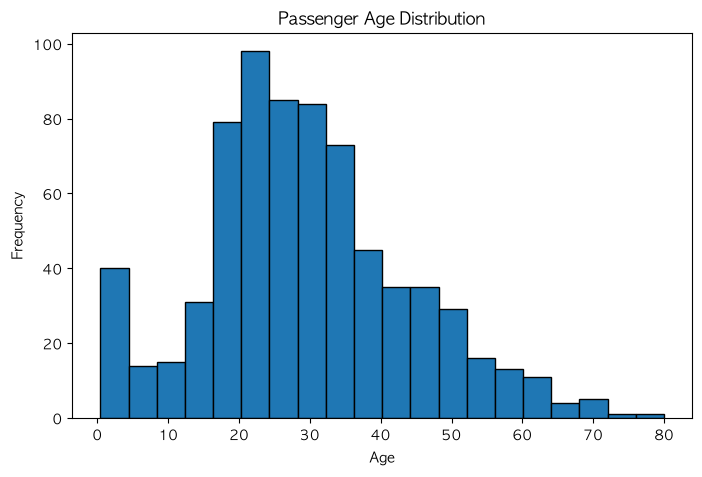

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["age"].dropna(), # 나이 중 결측치는 전부 제외
    bins = 20, # 나이 범위를 20개 구간으로 나눔
    edgecolor="black"
)

plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()